# **Análisis de factores de Detracción en la Carrera de Medicina**

**Importar paquetes**

In [145]:
import pandas as pd
import os
import sys
from datetime import datetime
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score, confusion_matrix
import seaborn as sns

**Preparación del acceso al Drive**

In [146]:
from google.colab import drive
drive.mount('/content/drive')


# Get the current directory of the notebook
current_dir = os.getcwd()

# Construct the path to the utilidadesML directory (assuming it's in the same directory as the notebook)
utilidadesML_path = os.path.join(current_dir, "drive/MyDrive/Colab Notebooks")

# Add the utilidadesML directory to the Python path
sys.path.append(utilidadesML_path)

import utilidadesML as ml

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Lectura de los datos**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
estudiantes = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/DATANPS2025.csv', sep=";")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Análisis de correlaciones para Detractores**

In [ ]:
estudiantes_Medicina = estudiantes[estudiantes['CAB3'] == 'Medicina Humana'].copy()
estudiantes_Medicina.info()

<class 'pandas.core.frame.DataFrame'>
Index: 500 entries, 643 to 7485
Data columns (total 76 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ID_COD                 500 non-null    int64  
 1   ID                     500 non-null    int64  
 2   X_CAMPUS               500 non-null    object 
 3   X_PERIODO              500 non-null    object 
 4   X_MODALIDAD            500 non-null    object 
 5   PROGRAMA               500 non-null    int64  
 6   X_FACULTAD             500 non-null    object 
 7   DESCRIPCION_PROGRAMA   500 non-null    object 
 8   PERIODO_ADMISION       500 non-null    int64  
 9   CATALOGO               500 non-null    int64  
 10  CICLO_ACTUAL           500 non-null    int64  
 11  CREDITOS_TOTAL         500 non-null    int64  
 12  CREDITOS_MATRICULADOS  500 non-null    int64  
 13  CACHIMBO               500 non-null    int64  
 14  REINCORPORADO          500 non-null    int64  
 15  TRASLADO

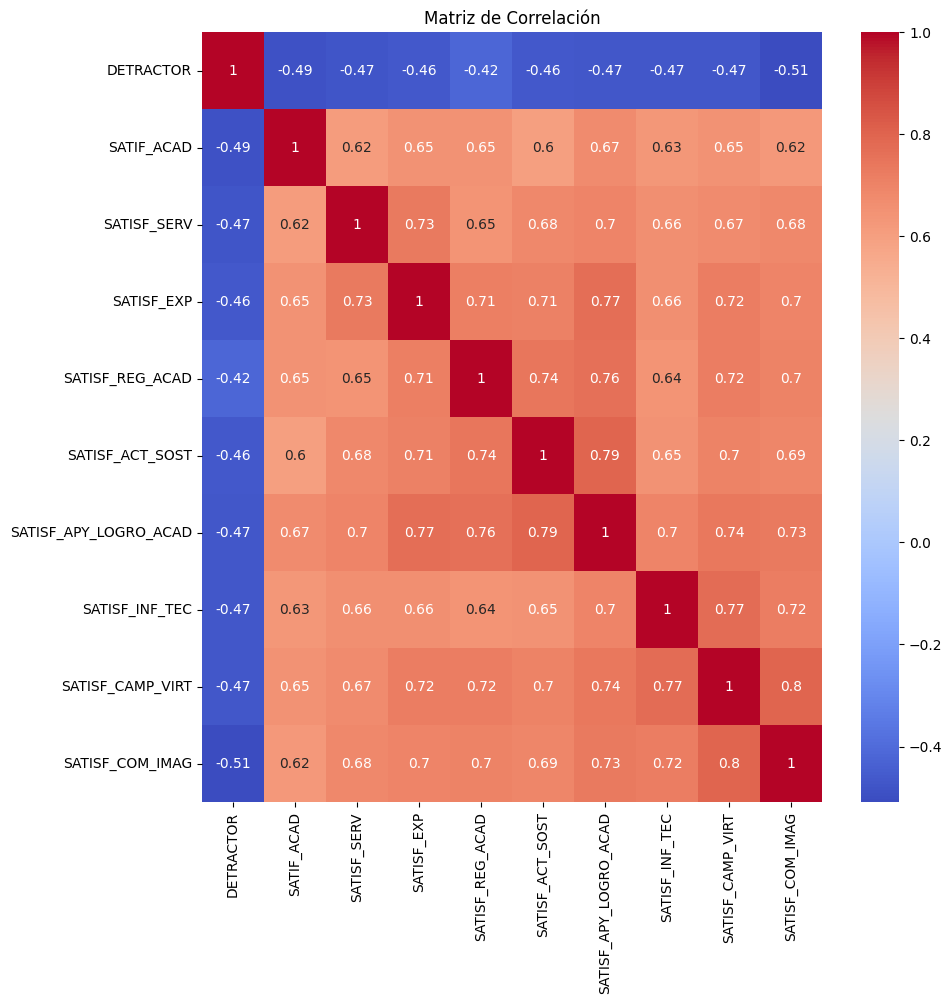

In [ ]:
copia = X = estudiantes_Medicina[['DETRACTOR', 'SATIF_ACAD', 'SATISF_SERV', 'SATISF_EXP', 'SATISF_REG_ACAD', 'SATISF_ACT_SOST', 'SATISF_APY_LOGRO_ACAD', 'SATISF_INF_TEC', 'SATISF_CAMP_VIRT', 'SATISF_COM_IMAG']]
plt.figure(figsize=(10, 10))
sns.heatmap(copia.corr(), annot=True, cmap='coolwarm')
plt.title('Matriz de Correlación')
plt.show()

**Preparación de conjuntos de extrenamiento y testing**

In [ ]:
X = estudiantes_Medicina[['SATIF_ACAD', 'SATISF_SERV', 'SATISF_EXP', 'SATISF_REG_ACAD', 'SATISF_ACT_SOST', 'SATISF_APY_LOGRO_ACAD', 'SATISF_INF_TEC', 'SATISF_CAMP_VIRT', 'SATISF_COM_IMAG']]
y = estudiantes_Medicina['DETRACTOR']
XCopia = X.copy()

**Pruebas T de Diferencia de Medias para refinar las columnas del Modelo el conjunto final queda en XCopia**

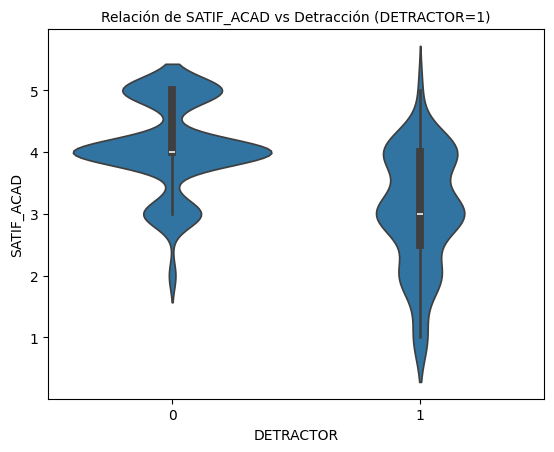

*** Prueba t para SATIF_ACAD ***
Estadístico t: -12.52878
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.079692
1    3.054054
Name: SATIF_ACAD, dtype: float64




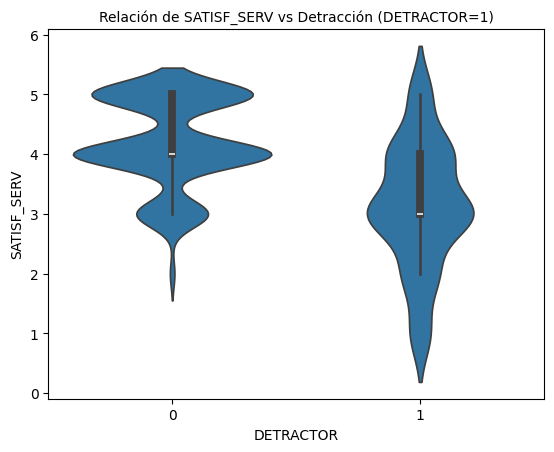

*** Prueba t para SATISF_SERV ***
Estadístico t: -11.99257
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.185090
1    3.135135
Name: SATISF_SERV, dtype: float64




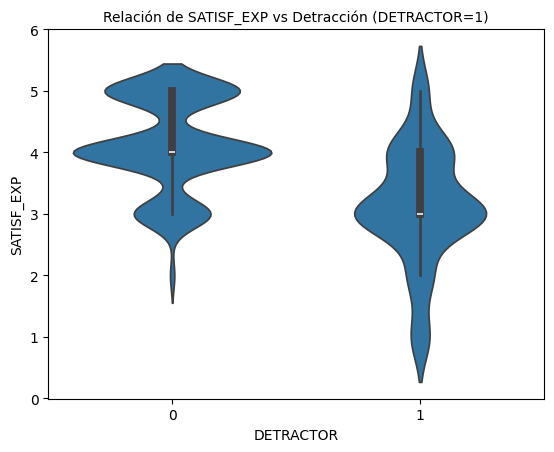

*** Prueba t para SATISF_EXP ***
Estadístico t: -11.67981
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.120823
1    3.135135
Name: SATISF_EXP, dtype: float64




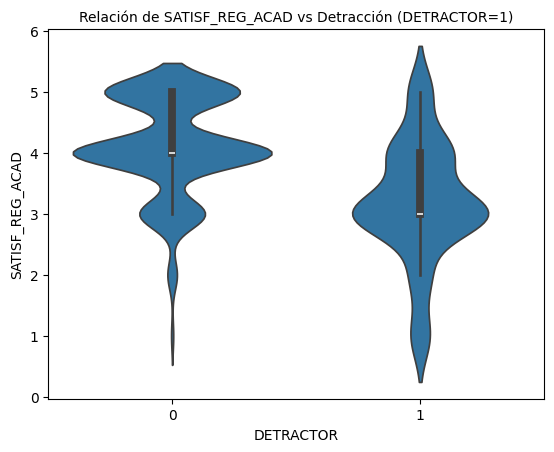

*** Prueba t para SATISF_REG_ACAD ***
Estadístico t: -10.18555
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.107969
1    3.198198
Name: SATISF_REG_ACAD, dtype: float64




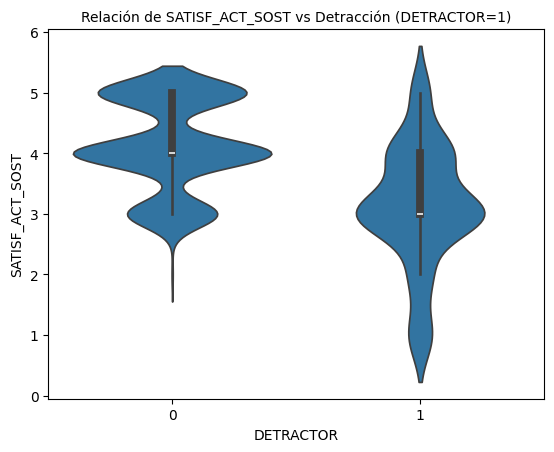

*** Prueba t para SATISF_ACT_SOST ***
Estadístico t: -11.66081
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.128535
1    3.126126
Name: SATISF_ACT_SOST, dtype: float64




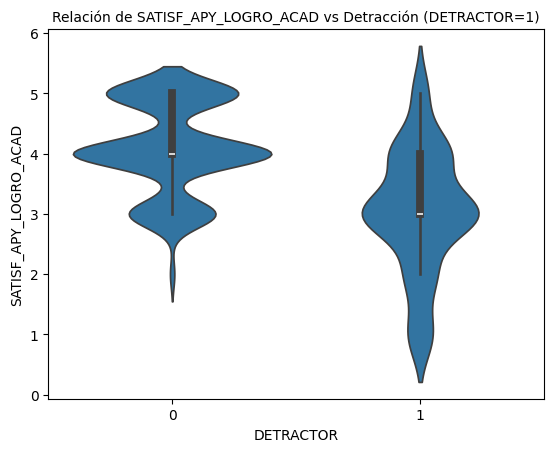

*** Prueba t para SATISF_APY_LOGRO_ACAD ***
Estadístico t: -11.93924
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.087404
1    3.045045
Name: SATISF_APY_LOGRO_ACAD, dtype: float64




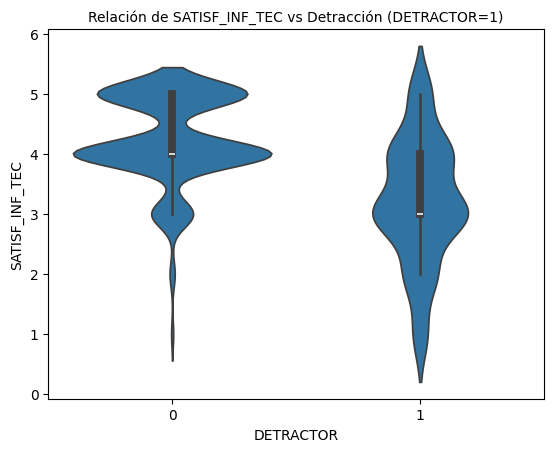

*** Prueba t para SATISF_INF_TEC ***
Estadístico t: -11.88383
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.231362
1    3.207207
Name: SATISF_INF_TEC, dtype: float64




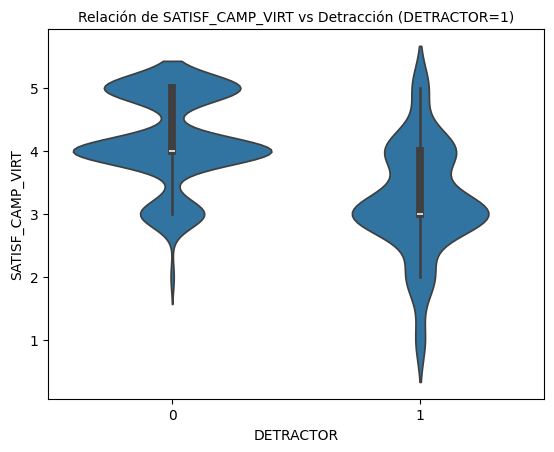

*** Prueba t para SATISF_CAMP_VIRT ***
Estadístico t: -11.83150
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.164524
1    3.216216
Name: SATISF_CAMP_VIRT, dtype: float64




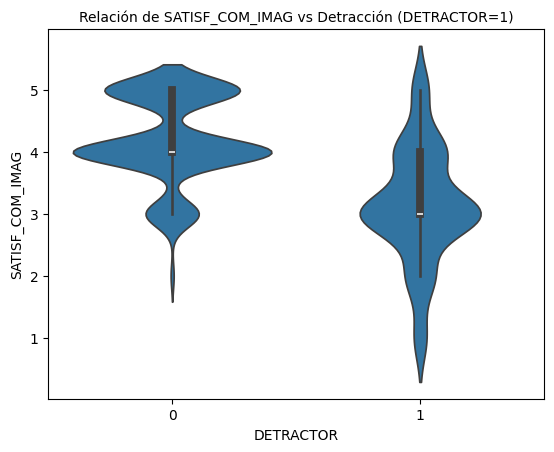

*** Prueba t para SATISF_COM_IMAG ***
Estadístico t: -13.18407
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.195373
1    3.135135
Name: SATISF_COM_IMAG, dtype: float64




In [ ]:
for column in X.columns:
    title = f"Relación de {column} vs Detracción (DETRACTOR=1)"
    ml.analisis_variable_violin(estudiantes_Medicina, "DETRACTOR", column, title)
    ml.prueba_t(estudiantes_Medicina, 'DETRACTOR', column, 1, 0, XCopia)

**Modelo de Regresión Logística para predecir Detractores**

Precisión del modelo con class_weight='balanced': 0.810
Reporte de clasificación con class_weight='balanced':
              precision    recall  f1-score   support

           0       0.90      0.84      0.87        75
           1       0.60      0.72      0.65        25

    accuracy                           0.81       100
   macro avg       0.75      0.78      0.76       100
weighted avg       0.82      0.81      0.82       100



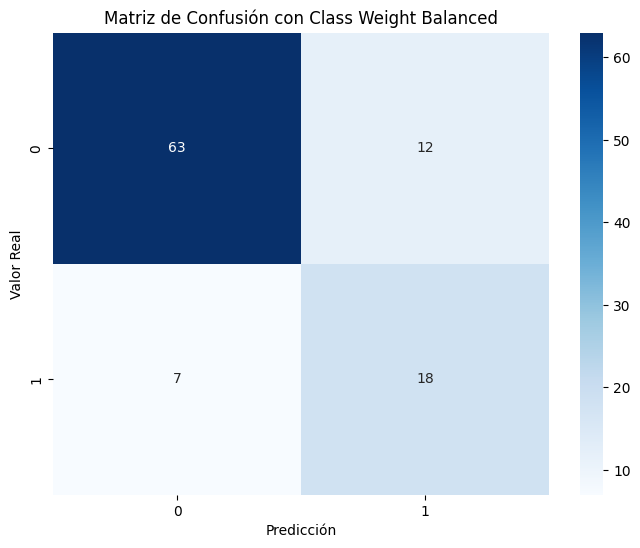

In [ ]:
# Modelo de Regresión Logística con class_weight='balanced'
# Esto asignará automáticamente pesos inversamente proporcionales a las frecuencias de clase.

X_train, X_test, y_train, y_test = train_test_split(XCopia, y, test_size=0.20, random_state=42)

model_balanced = LogisticRegression(solver='liblinear', max_iter=300, random_state=50, class_weight='balanced')

model_balanced.fit(X_train, y_train)

y_pred_balanced = model_balanced.predict(X_test)
accuracy_balanced = accuracy_score(y_test, y_pred_balanced)
report_balanced = classification_report(y_test, y_pred_balanced)

print(f'Precisión del modelo con class_weight=\'balanced\': {accuracy_balanced:.3f}')
print(f'Reporte de clasificación con class_weight=\'balanced\':\n{report_balanced}')

# Graficar la matriz de confusión
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_balanced), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión con Class Weight Balanced')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()

### **Análisis de la Importancia de las Variables (`model_balanced`)**

SATIF_ACAD: -0.60
SATISF_SERV: -0.24
SATISF_EXP: -0.19
SATISF_REG_ACAD: 0.30
SATISF_ACT_SOST: -0.35
SATISF_APY_LOGRO_ACAD: 0.09
SATISF_INF_TEC: -0.02
SATISF_CAMP_VIRT: -0.02
SATISF_COM_IMAG: -0.49


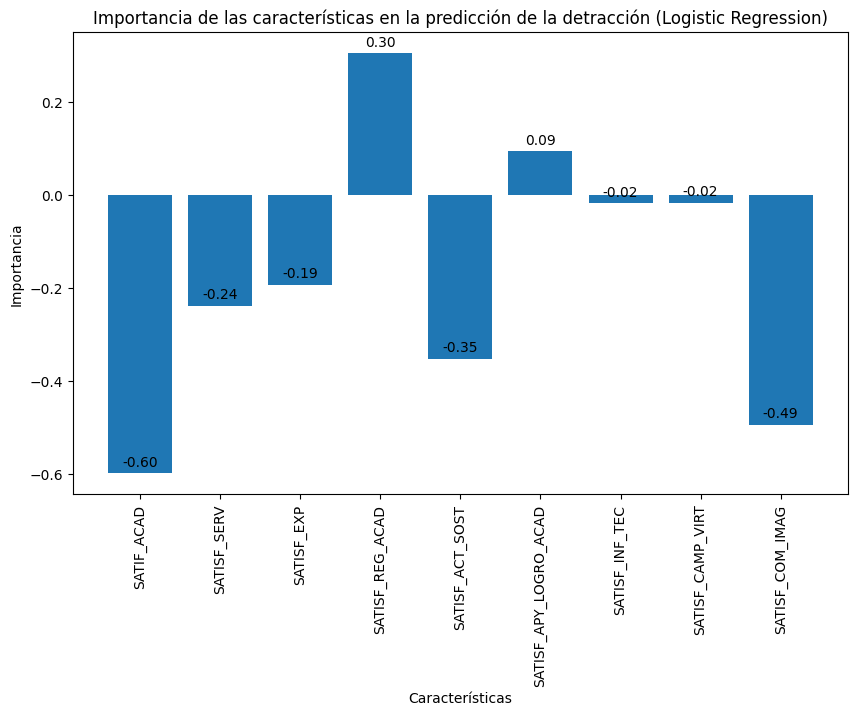

In [ ]:
feature_importance = model_balanced.coef_[0]

for i in range(0, len(XCopia.columns)):
    print(f"{XCopia.columns[i]}: {feature_importance[i]:.2f}")

plt.figure(figsize=(10, 6))
bars = plt.bar(XCopia.columns, feature_importance)
plt.xlabel('Características')
plt.ylabel('Importancia')
plt.title('Importancia de las características en la predicción de la detracción (Logistic Regression)')

for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{height:.2f}', xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom')

plt.xticks(rotation=90)
plt.show()

### **Análisis SHAP para `model_balanced`**

  0%|          | 0/100 [00:00<?, ?it/s]

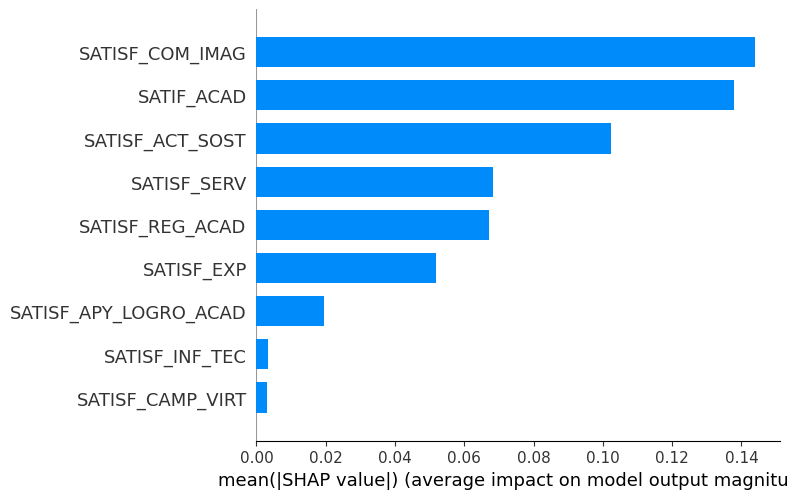

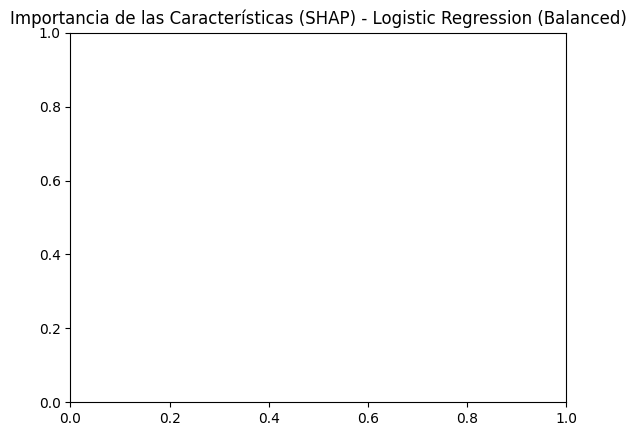

In [ ]:
import shap

explainer = shap.KernelExplainer(model_balanced.predict, X_train)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns, plot_type="bar")
plt.title('Importancia de las Características (SHAP) - Logistic Regression (Balanced)')
plt.show()

**Análisis de Deep Learning para ver impacto de las variables en el modelo**

  0%|          | 0/100 [00:00<?, ?it/s]

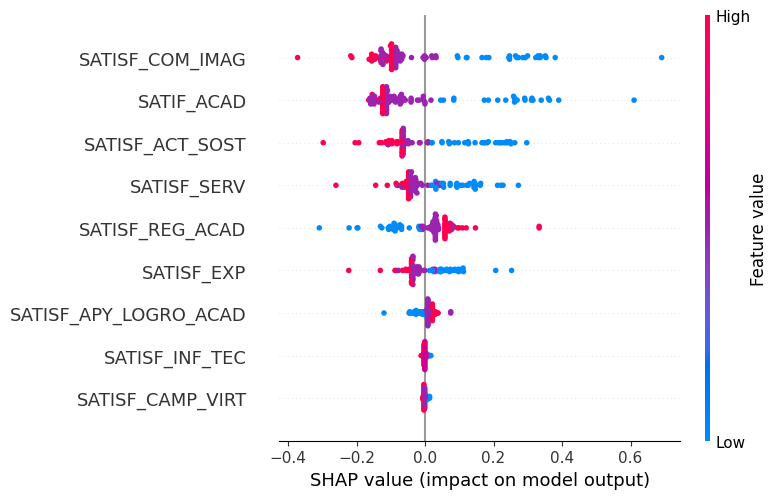

In [ ]:
import shap

explainer = shap.KernelExplainer(model_balanced.predict, X_train)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns)

# **Análisis de los factores de Satisfacción con la Imagen y Comunicación de la universidad**

**P26. ¿QUÉ TAN SATISFECHO TE ENCUENTRAS CON CADA UNO DE LOS ASPECTOS DE LA COMUNICACIÓN E IMAGEN   DE LA UNIVERSIDAD CONTINENTAL?**

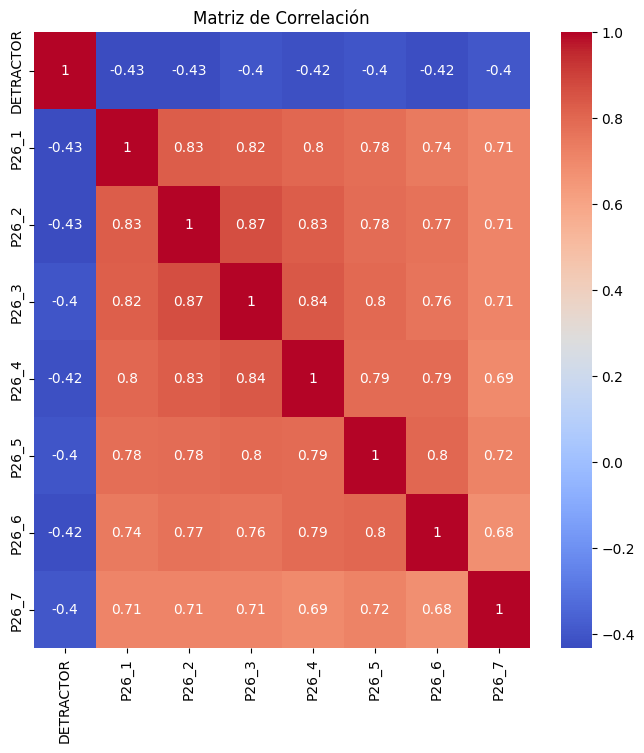

In [ ]:
copia = X = estudiantes_Medicina[['DETRACTOR','P26_1','P26_2','P26_3','P26_4','P26_5','P26_6','P26_7']]
plt.figure(figsize=(8, 8))
sns.heatmap(copia.corr(), annot=True, cmap='coolwarm')
plt.title('Matriz de Correlación')
plt.show()

In [ ]:
X = estudiantes_Medicina[['P26_1','P26_2','P26_3','P26_4','P26_5','P26_6','P26_7']]
y = estudiantes_Medicina['DETRACTOR']
XCopia = X.copy()

**Pruebas T de Diferencia de Medias para refinar las columnas del Modelo el conjunto final queda en XCopia**

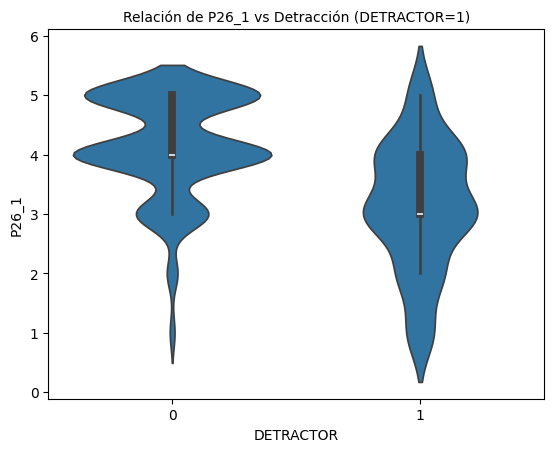

*** Prueba t para P26_1 ***
Estadístico t: -10.62202
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.146530
1    3.126126
Name: P26_1, dtype: float64




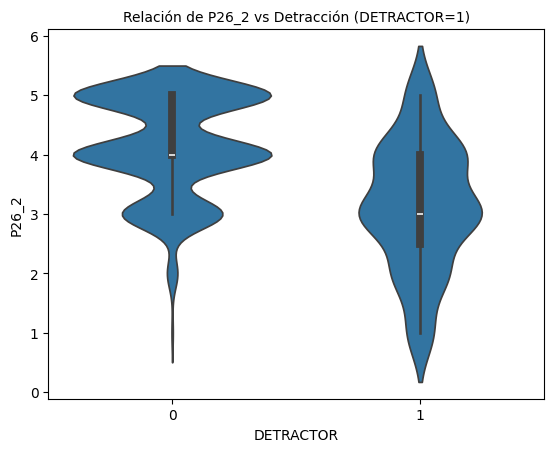

*** Prueba t para P26_2 ***
Estadístico t: -10.72397
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.141388
1    3.126126
Name: P26_2, dtype: float64




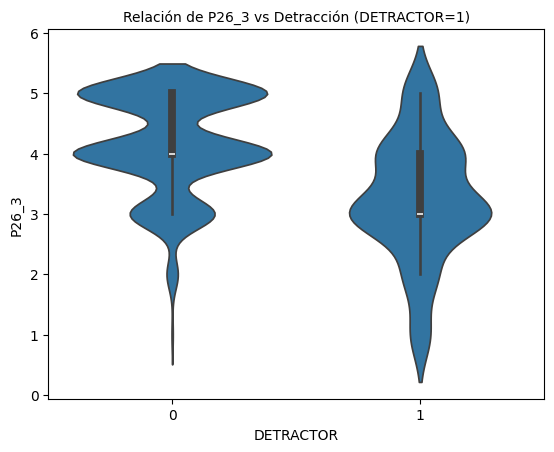

*** Prueba t para P26_3 ***
Estadístico t: -9.86466
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.161954
1    3.252252
Name: P26_3, dtype: float64




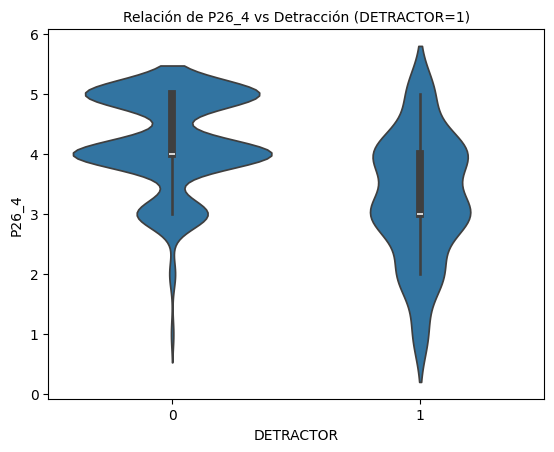

*** Prueba t para P26_4 ***
Estadístico t: -10.25844
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.187661
1    3.261261
Name: P26_4, dtype: float64




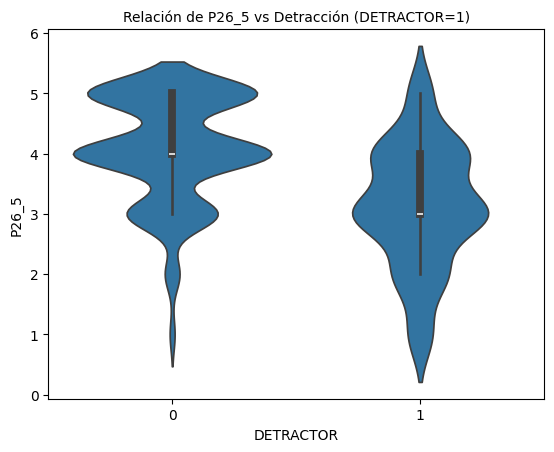

*** Prueba t para P26_5 ***
Estadístico t: -9.73217
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.071979
1    3.126126
Name: P26_5, dtype: float64




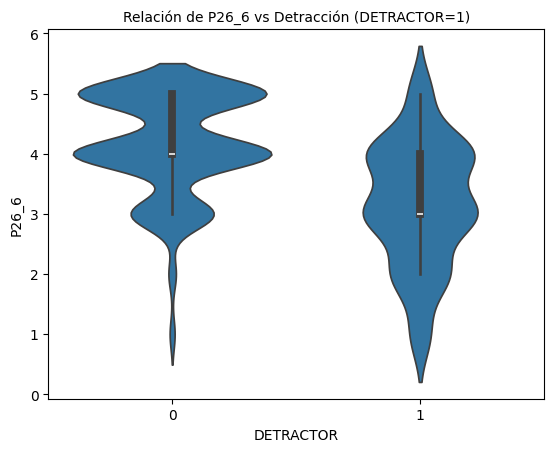

*** Prueba t para P26_6 ***
Estadístico t: -10.44196
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.156812
1    3.171171
Name: P26_6, dtype: float64




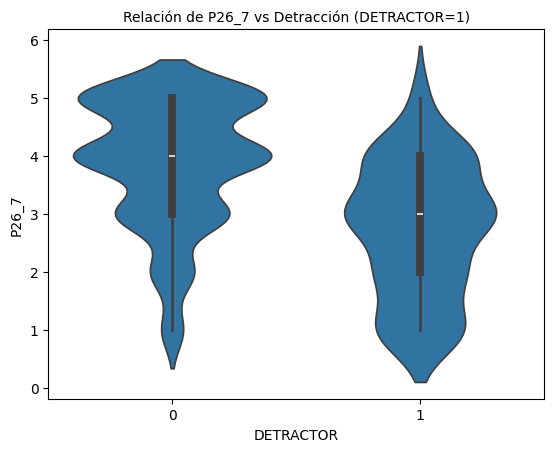

*** Prueba t para P26_7 ***
Estadístico t: -9.60354
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    3.863753
1    2.729730
Name: P26_7, dtype: float64




In [ ]:
for column in X.columns:
    title = f"Relación de {column} vs Detracción (DETRACTOR=1)"
    ml.analisis_variable_violin(estudiantes_Medicina, "DETRACTOR", column, title)
    ml.prueba_t(estudiantes_Medicina, 'DETRACTOR', column, 1, 0, XCopia)

Precisión del modelo con class_weight='balanced': 0.820
Reporte de clasificación con class_weight='balanced':
              precision    recall  f1-score   support

           0       0.89      0.87      0.88        75
           1       0.63      0.68      0.65        25

    accuracy                           0.82       100
   macro avg       0.76      0.77      0.77       100
weighted avg       0.83      0.82      0.82       100



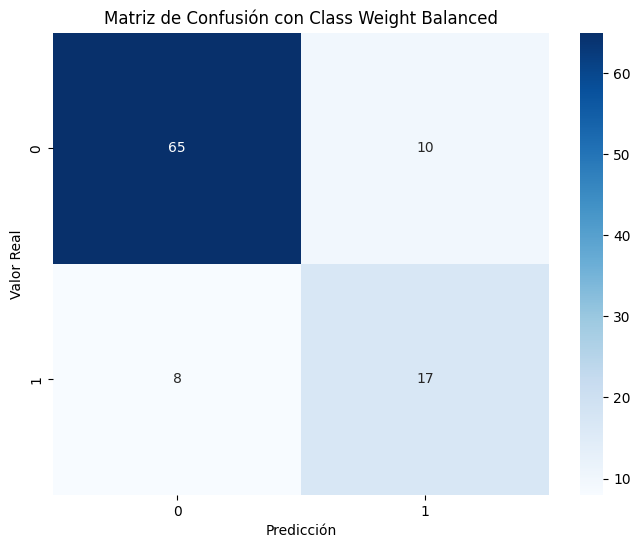

In [ ]:
# Modelo de Regresión Logística con class_weight='balanced'
# Esto asignará automáticamente pesos inversamente proporcionales a las frecuencias de clase.

X_train, X_test, y_train, y_test = train_test_split(XCopia, y, test_size=0.20, random_state=42)

model_balanced = LogisticRegression(solver='liblinear', max_iter=300, random_state=50, class_weight='balanced')

model_balanced.fit(X_train, y_train)

y_pred_balanced = model_balanced.predict(X_test)
accuracy_balanced = accuracy_score(y_test, y_pred_balanced)
report_balanced = classification_report(y_test, y_pred_balanced)

print(f'Precisión del modelo con class_weight=\'balanced\': {accuracy_balanced:.3f}')
print(f'Reporte de clasificación con class_weight=\'balanced\':\n{report_balanced}')

# Graficar la matriz de confusión
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_balanced), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión con Class Weight Balanced')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()

**26.1 COMUNICACIÓN OPORTUNA A LOS ESTUDIANTES DE LOS BENEFICIOS, ESTÍMULOS Y NORMATIVAS DE LA UNIVERSIDAD**

**26.6 COMUNICACIÓN DE LOGROS DE LA UNIVERSIDAD**

**26.7 MONTO DE LA PENSIÓN**

  0%|          | 0/100 [00:00<?, ?it/s]

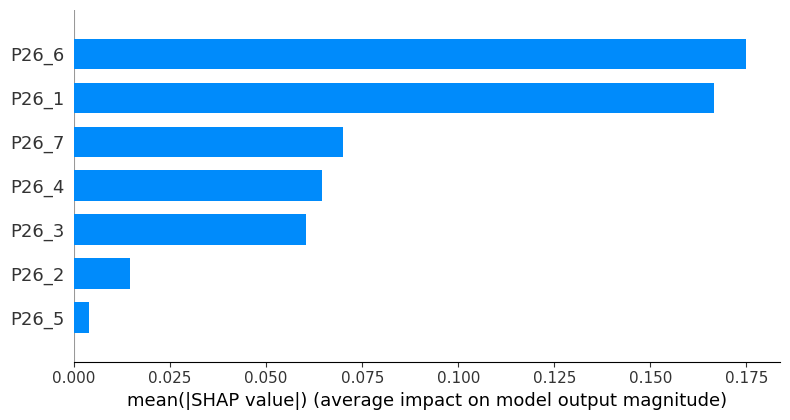

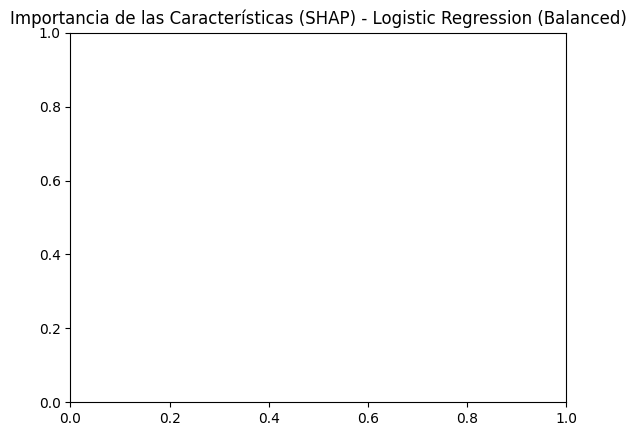

In [ ]:
import shap

explainer = shap.KernelExplainer(model_balanced.predict, X_train)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns, plot_type="bar")
plt.title('Importancia de las Características (SHAP) - Logistic Regression (Balanced)')
plt.show()

**Si ves puntos rojos en el lado izquierdo y azules en el derecho esto significa valores altos de la característica disminuyen la probabilidad de ser detractor y valores bajos la aumentan**

  0%|          | 0/100 [00:00<?, ?it/s]

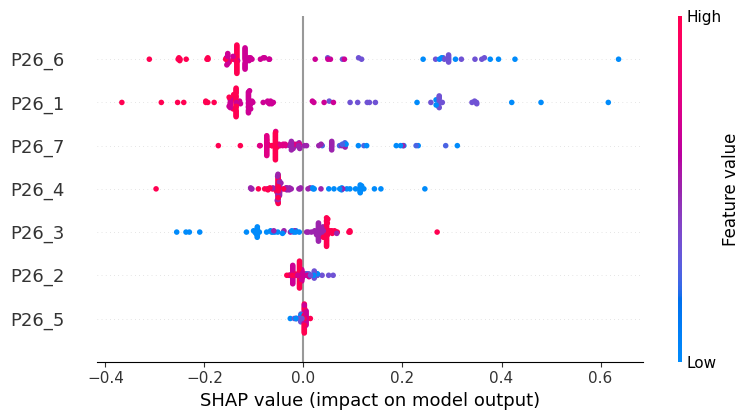

In [ ]:
import shap

explainer = shap.KernelExplainer(model_balanced.predict, X_train)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns)

# **Análisis de los factores de Satisfacción lo académico**
**P3. ¿QUÉ TAN SATISFECHO TE ENCUENTRAS CON EL ÁREA ACADÉMICA DE LA UNIVERSIDAD CONTINENTAL?**

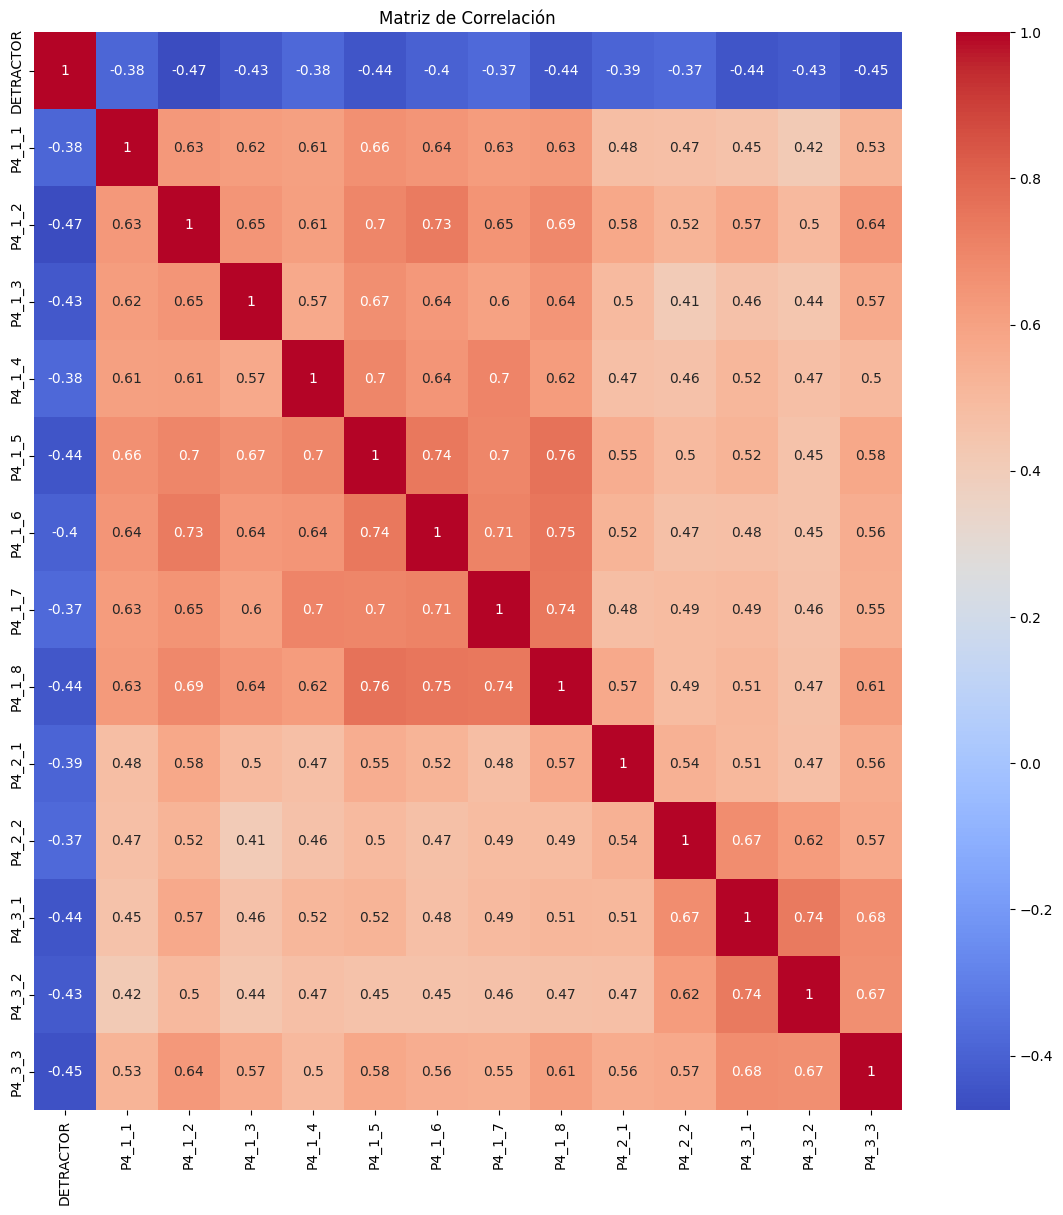

In [ ]:
copia = X = estudiantes_Medicina[['DETRACTOR','P4_1_1','P4_1_2','P4_1_3','P4_1_4','P4_1_5','P4_1_6','P4_1_7','P4_1_8','P4_2_1','P4_2_2','P4_3_1','P4_3_2','P4_3_3']]
plt.figure(figsize=(14, 14))
sns.heatmap(copia.corr(), annot=True, cmap='coolwarm')
plt.title('Matriz de Correlación')
plt.show()

In [ ]:
X = estudiantes_Medicina[['P4_1_1','P4_1_2','P4_1_3','P4_1_4','P4_1_5','P4_1_6','P4_1_7','P4_1_8','P4_2_1','P4_2_2','P4_3_1','P4_3_2','P4_3_3']]
y = estudiantes_Medicina['DETRACTOR']
XCopia = X.copy()

**Pruebas T de Diferencia de Medias para refinar las columnas del Modelo el conjunto final queda en XCopia**

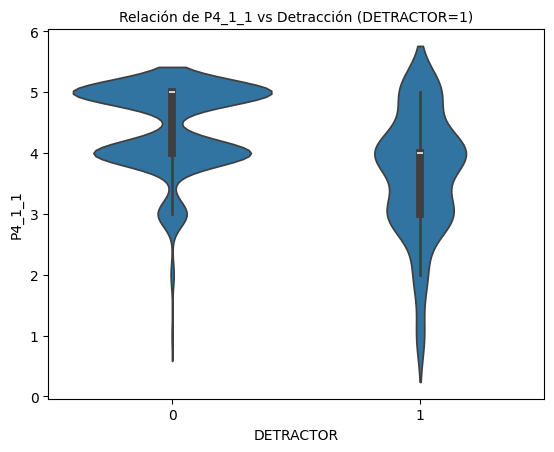

*** Prueba t para P4_1_1 ***
Estadístico t: -9.25138
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.413882
1    3.657658
Name: P4_1_1, dtype: float64




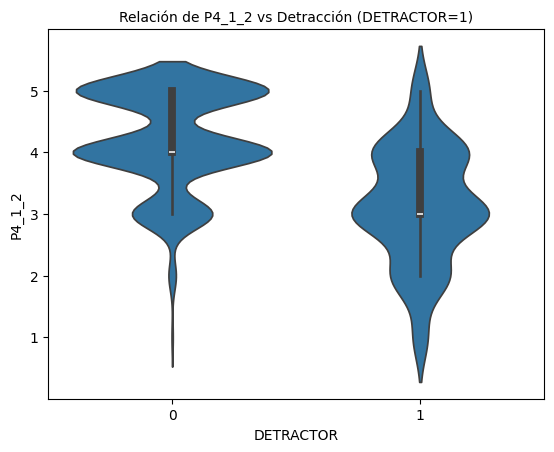

*** Prueba t para P4_1_2 ***
Estadístico t: -12.02860
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.195373
1    3.135135
Name: P4_1_2, dtype: float64




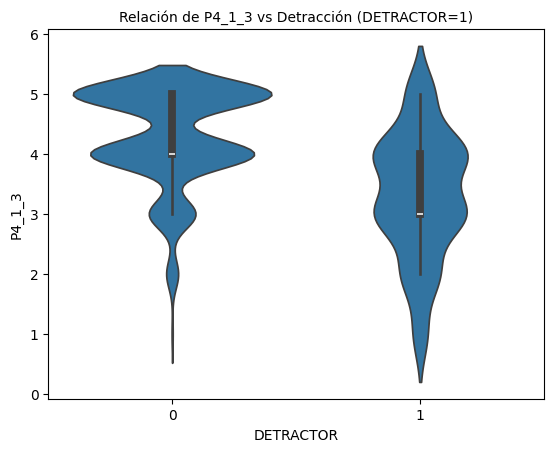

*** Prueba t para P4_1_3 ***
Estadístico t: -10.70035
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.295630
1    3.315315
Name: P4_1_3, dtype: float64




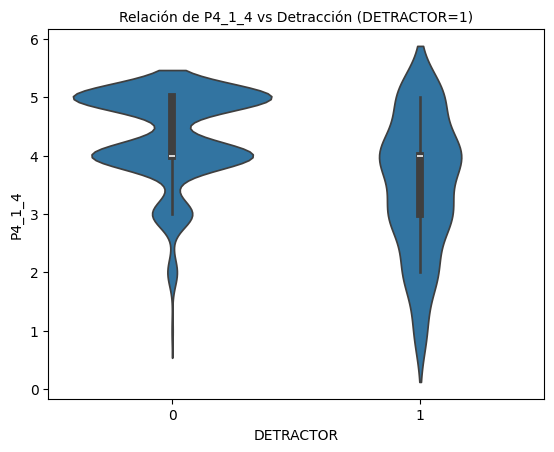

*** Prueba t para P4_1_4 ***
Estadístico t: -9.13684
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.331620
1    3.486486
Name: P4_1_4, dtype: float64




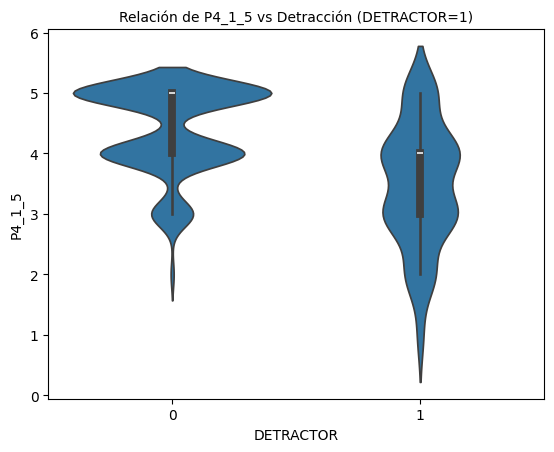

*** Prueba t para P4_1_5 ***
Estadístico t: -10.93856
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.388175
1    3.468468
Name: P4_1_5, dtype: float64




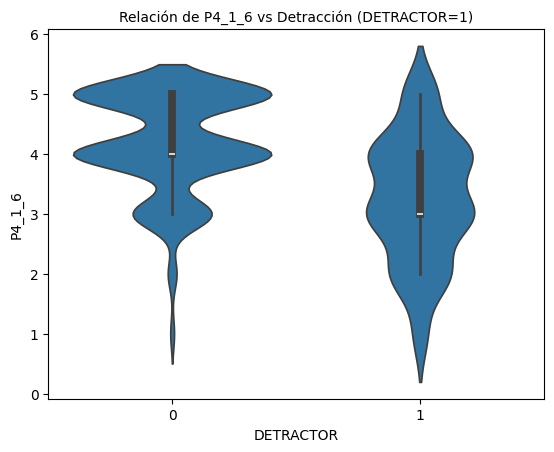

*** Prueba t para P4_1_6 ***
Estadístico t: -9.82676
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.185090
1    3.261261
Name: P4_1_6, dtype: float64




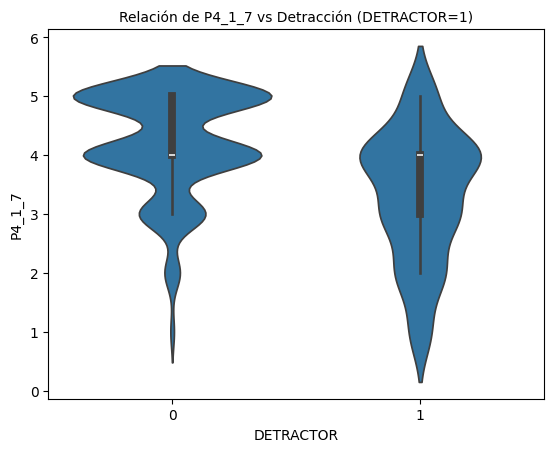

*** Prueba t para P4_1_7 ***
Estadístico t: -8.91477
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.195373
1    3.315315
Name: P4_1_7, dtype: float64




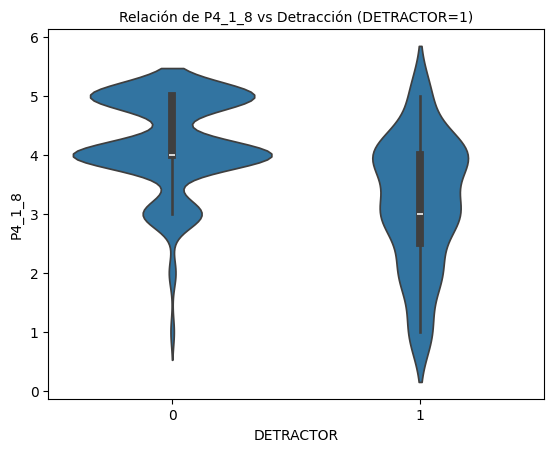

*** Prueba t para P4_1_8 ***
Estadístico t: -10.80773
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.190231
1    3.189189
Name: P4_1_8, dtype: float64




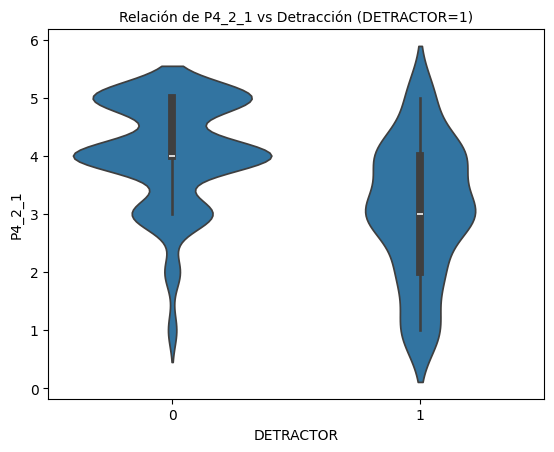

*** Prueba t para P4_2_1 ***
Estadístico t: -9.44970
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.048843
1    3.072072
Name: P4_2_1, dtype: float64




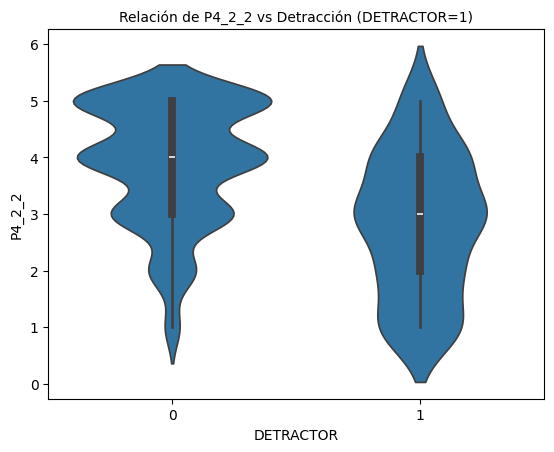

*** Prueba t para P4_2_2 ***
Estadístico t: -8.99223
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    3.892031
1    2.828829
Name: P4_2_2, dtype: float64




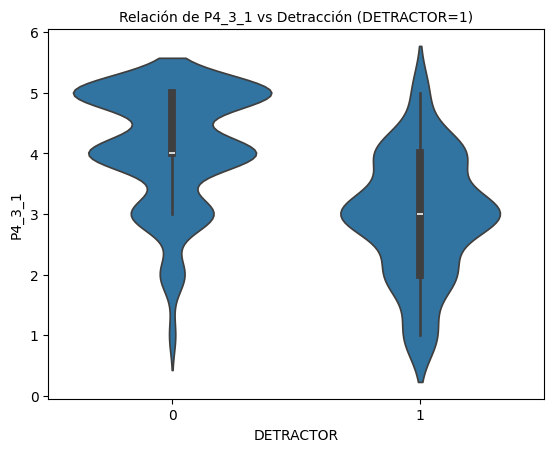

*** Prueba t para P4_3_1 ***
Estadístico t: -11.02361
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.100257
1    2.963964
Name: P4_3_1, dtype: float64




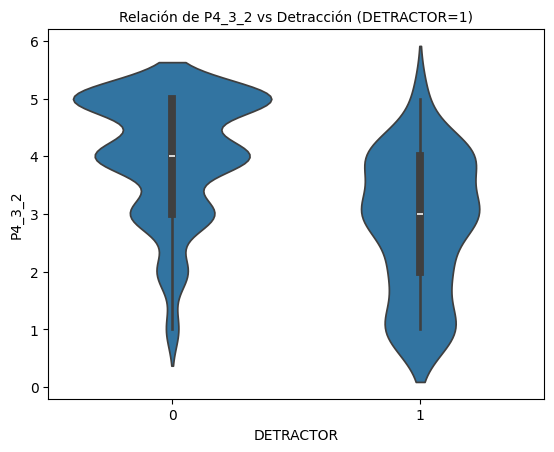

*** Prueba t para P4_3_2 ***
Estadístico t: -10.55115
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.033419
1    2.819820
Name: P4_3_2, dtype: float64




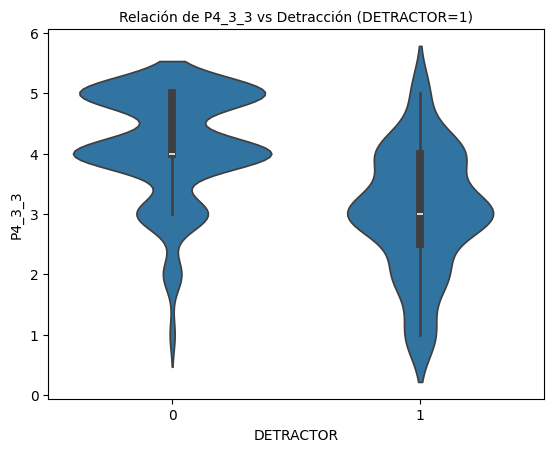

*** Prueba t para P4_3_3 ***
Estadístico t: -11.31829
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.131105
1    3.027027
Name: P4_3_3, dtype: float64




In [ ]:
for column in X.columns:
    title = f"Relación de {column} vs Detracción (DETRACTOR=1)"
    ml.analisis_variable_violin(estudiantes_Medicina, "DETRACTOR", column, title)
    ml.prueba_t(estudiantes_Medicina, 'DETRACTOR', column, 1, 0, XCopia)

Precisión del modelo con class_weight='balanced': 0.793
Reporte de clasificación con class_weight='balanced':
              precision    recall  f1-score   support

           0       0.91      0.82      0.86       117
           1       0.52      0.70      0.60        33

    accuracy                           0.79       150
   macro avg       0.71      0.76      0.73       150
weighted avg       0.82      0.79      0.80       150



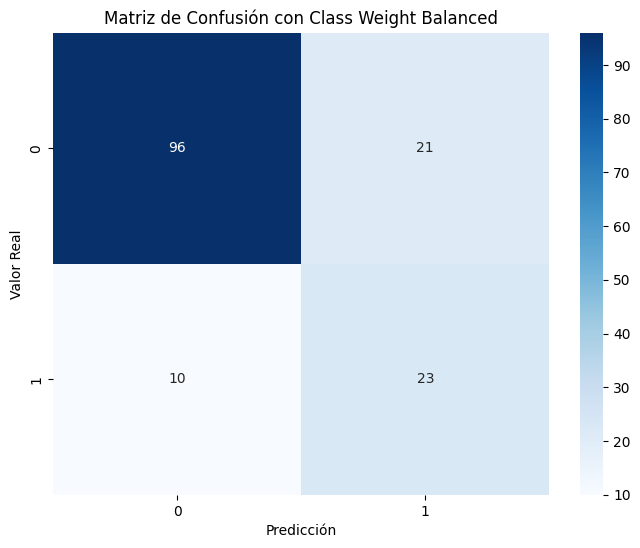

In [ ]:
# Modelo de Regresión Logística con class_weight='balanced'
# Esto asignará automáticamente pesos inversamente proporcionales a las frecuencias de clase.

X_train, X_test, y_train, y_test = train_test_split(XCopia, y, test_size=0.3, random_state=42)

model_balanced = LogisticRegression(solver='liblinear', max_iter=300, random_state=50, class_weight='balanced')

model_balanced.fit(X_train, y_train)

y_pred_balanced = model_balanced.predict(X_test)
accuracy_balanced = accuracy_score(y_test, y_pred_balanced)
report_balanced = classification_report(y_test, y_pred_balanced)

print(f'Precisión del modelo con class_weight=\'balanced\': {accuracy_balanced:.3f}')
print(f'Reporte de clasificación con class_weight=\'balanced\':\n{report_balanced}')

# Graficar la matriz de confusión
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_balanced), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión con Class Weight Balanced')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()

**4.1.2 METODOLOGÍA DE LA ENSEÑANZA TEÓRICA/PRÁCTICA.**

**4.3.2 FACILIDAD PARA ADELANTAR ASIGNATURAS DE LA CARRERA.**

**4.3.1 FLEXIBILIDAD PARA LA ELECCIÓN DE ASIGNATURAS DEL PLAN DE ESTUDIOS.**

  0%|          | 0/150 [00:00<?, ?it/s]

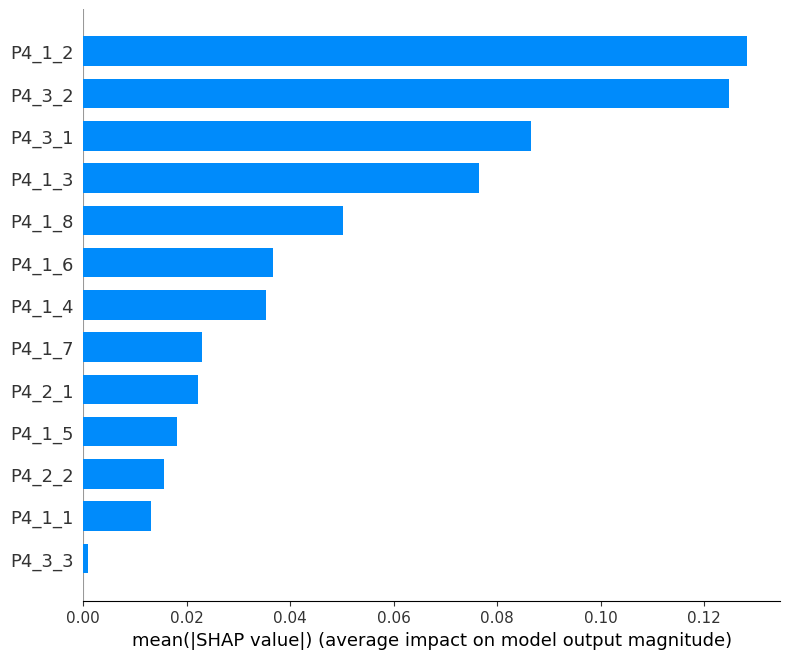

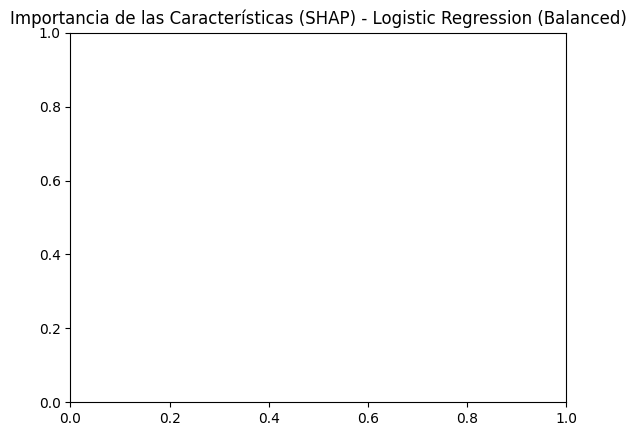

In [ ]:
import shap

explainer = shap.KernelExplainer(model_balanced.predict, X_train)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns, plot_type="bar")
plt.title('Importancia de las Características (SHAP) - Logistic Regression (Balanced)')
plt.show()

**Si ves puntos rojos en el lado izquierdo y azules en el derecho esto significa valores altos de la característica disminuyen la probabilidad de ser detractor y valores bajos la aumentan**

  0%|          | 0/150 [00:00<?, ?it/s]

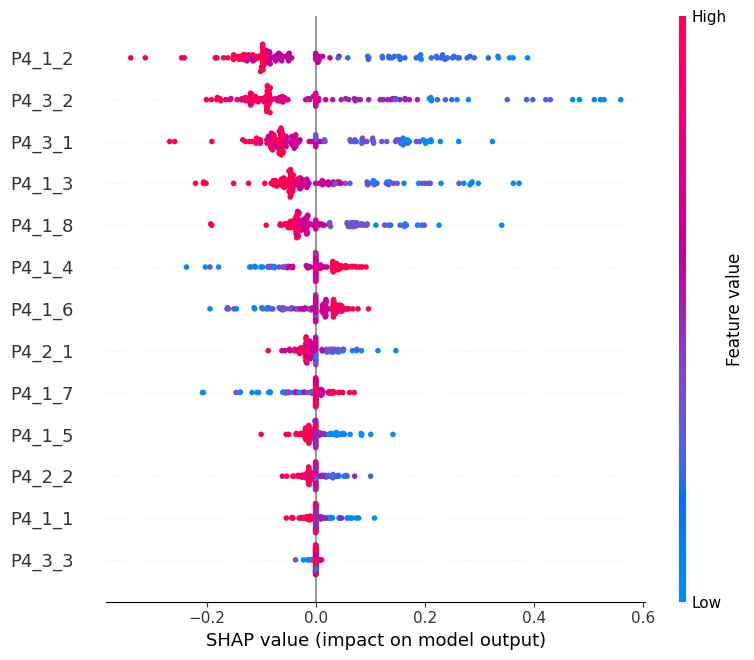

In [ ]:
explainer = shap.KernelExplainer(model_balanced.predict, X_train)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns)